# 01 · Preprocessing — Galen 2019 Acute Myeloid Leukemia (malignant compartment)

Isolate malignant blasts, threshold thin samples by a **data-driven cliff**, integrate
patients (Harmony), embed, remove detached islands, and split the manifold into its
transcriptional compartments. AML blasts are strongly patient-segregated by leukaemia
genetics, so batch integration and its verification carry the Gate-1 decision here; the
read is made on the **regenerated embedding** plus a per-neighbourhood mixing metric
(iLISI) across an integration-strength sweep, never a scalar alone. As in the reference
runs the manifold resolves into a **cycling** lobe and a **low-cycling** lobe; whether
the trajectory is scoped to one lobe or spans both is decided in 02 from the signature
geography, not assumed here. Every tunable choice is *derived from this dataset*, not
inherited. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)        # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)  # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Galen2019_Hematologic | category: Hematologic


### Load malignant compartment
Galen et al. annotate cell type directly (SeqWell bone-marrow aspirates); we take their
`Malignant` blast calls. Counts are `normalize_total`-normalised then `log1p` by the loader.

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Galen2019_Hematologic
Done.
full atlas: (33392, 27899)
malignant: (16169, 27899) | samples: 28
expression: X max 7.38 (log1p of normalize_total counts)


### Sample thresholding — derived from the count cliff (assumption made explicit)
The reference multiplicative-gap rule assumes the sorted per-sample counts have a single
clean cliff. That premise **fails here**: a long tail of spillover samples (≤16 cells,
down to singletons) makes the global argmax multiplicative ratio land in the noise tail
(5→1), which is meaningless. We therefore restrict gap-finding to samples that can
contribute local structure — at least one kNN neighbourhood (`n_neighbors=30`) — and cut
at the geometric mean of the resulting cliff. On this data that cliff is a clean
**61→16** step (ratio ≈3.8), separating tumour-bearing marrows from spillover.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
NN = 30                                    # kNN neighbourhood size used downstream
ratios = vals[:-1] / vals[1:]
# gap-finding restricted to the viability-relevant range (larger side of a gap >= NN):
cand = [(i, ratios[i]) for i in range(len(ratios)) if vals[i] >= NN and vals[i+1] < NN]
gi = max(cand, key=lambda x: x[1])[0] if cand else int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gi] * vals[gi+1]))
print('sorted per-sample counts:', n.values.tolist())
print(f'viable-range cliff: {int(vals[gi])} -> {int(vals[gi+1])} (ratio {ratios[gi]:.2f})')
print(f'derived threshold (geometric mean across the cliff) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [3378, 2062, 1502, 1370, 1178, 1145, 1068, 856, 775, 693, 464, 314, 308, 259, 253, 161, 153, 100, 61, 16, 15, 13, 10, 7, 5, 1, 1, 1]
viable-range cliff: 61 -> 16 (ratio 3.81)
derived threshold (geometric mean across the cliff) = 31
kept 19/28 samples -> 16100 cells


### Overdispersion, PCA, Harmony integration, embedding
`theta` is chosen by an **iLISI** sweep — the per-neighbourhood inverse-Simpson
effective number of samples (higher = better mixing; ceiling = the compositional
effective sample count). We take the strongest integration at which iLISI plateaus
before collapsing. PC count (20) and UMAP spread (1.3) follow the comparable-size
precedents; `n_neighbors=30`.

*Determinism note:* Harmony's KMeans is not seed-deterministic, so iLISI values shift
by ≈±0.3 between reruns. That tolerance does not move the plateau location (θ=10) nor the
Gate-1 GO.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
NP = 20

from sklearn.neighbors import NearestNeighbors
def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum()
        out[i] = 1.0/np.sum(p**2)          # inverse Simpson = effective #samples in nbhd
    return out.mean()
p_glob = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1.0/np.sum(p_glob**2)
pre = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['sample'].values)
sweep = {}
for th in [1, 2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
print(f'#samples={adata.obs["sample"].nunique()} | iLISI ceiling (perfect mixing) = {ceiling:.2f}')
print('iLISI | pre-Harmony %.2f' % pre, '| sweep', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(iLISI plateaus then drops at 20; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 618 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 618
2026-08-03 17:07:06,515 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 17:07:08,354 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-03 17:07:08,499 - harmonypy - INFO - Iteration 1 of 30
2026-08-03 17:07:15,064 - harmonypy - INFO - Iteration 2 of 30
2026-08-03 17:07:20,825 - harmonypy - INFO - Iteration 3 of 30
2026-08-03 17:07:26,643 - harmonypy - INFO - Iteration 4 of 30
2026-08-03 17:07:32,147 - harmonypy - INFO - Converged after 4 iterations
2026-08-03 17:07:33,301 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-03 17:07:3

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any
cell outside the main connected component — stripping physically detached specks while
keeping the continuous arm termini.

In [6]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()

removed 1 cells in 1 detached islands


### Compartment split + labelling (data-driven)
Low-resolution Leiden (res=0.15) recovers two lobes. We label them *by biology*: the
compartment with the **lower cycling fraction** is the low-cycling lobe, the other is
cycling. `cell_cycle_phase` comes from the publication's phase calls. Whether the
trajectory is scoped to one lobe or spans both is decided in 02 from the signature
geography, not assumed here.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
lo_lobe = cyc.idxmin()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
lab_map = {l: ('Low-cycling' if l==lo_lobe else 'Cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 9872, '1': 6227}
cycling fraction per lobe: {'0': 0.245, '1': 0.043}
compartments: {'Cycling': 9872, 'Low-cycling': 6227}


### Gate 1 — batch mixing & manifold continuity
Read on the regenerated embedding itself (not a scalar). Two conditions must both hold:
**mixed** (no per-patient islands — the hard case for AML) and **continuous** (one
connected gradient). The iLISI sweep above quantifies mixing per neighbourhood; the
embedding below shows samples salt-and-peppered across one continuous mass and a
connected differentiation gradient in the blast subtypes.

19 samples share one continuous manifold; every neighbourhood mixes samples (iLISI 5.66 of 9.95 ceiling).
radius-graph detached islands removed above: one connected component retained.
Gate 1: samples intermixed on one continuous manifold -> GO


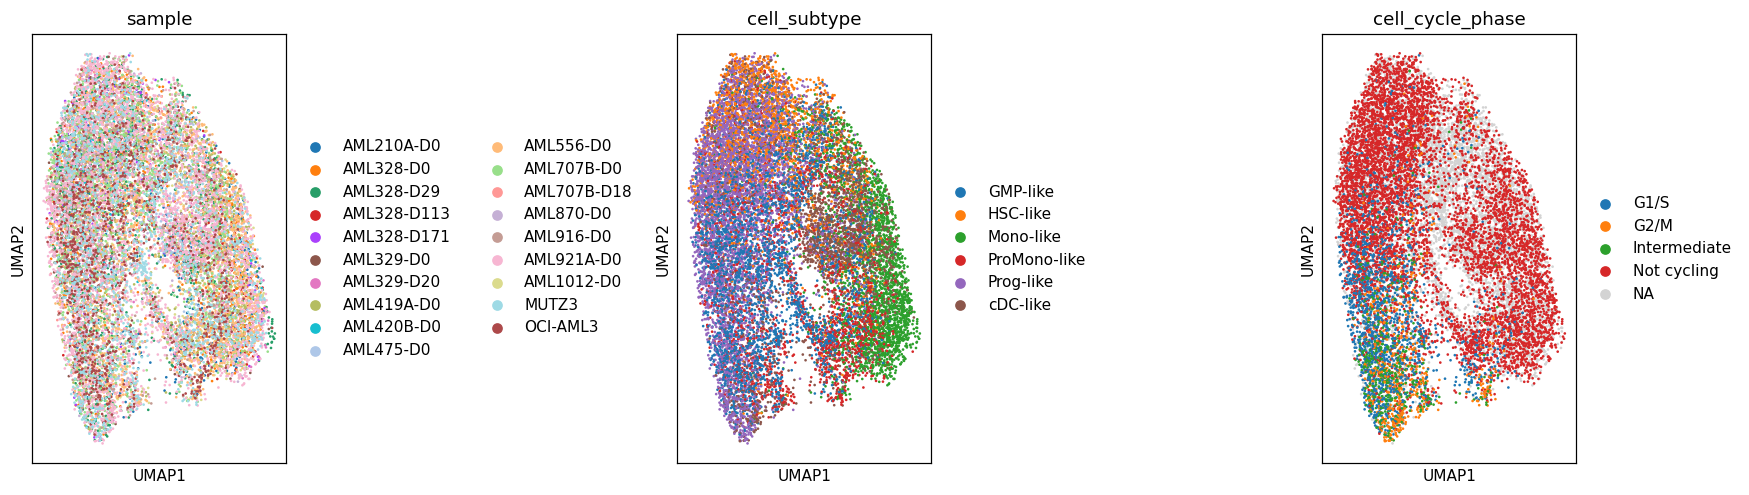

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
sc.pl.umap(adata, color='sample', size=12, ax=axes[0], show=False, title='sample')
sc.pl.umap(adata, color='cell_subtype', size=12, ax=axes[1], show=False, title='cell_subtype')
sc.pl.umap(adata, color='cell_cycle_phase', size=12, ax=axes[2], show=False, title='cell_cycle_phase')
fig.tight_layout()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous manifold; every neighbourhood mixes samples '
      f'(iLISI {sweep[theta]:.2f} of {ceiling:.2f} ceiling).')
print('radius-graph detached islands removed above: one connected component retained.')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

### Save processed data

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (16099, 20166)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)`, `size=30`) to match every trajectory panel. Colour =
sample: intermixing across the manifold is the Gate-1 batch-integration evidence.
Orientation is immaterial for this categorical panel (the pseudotime-oriented layout is
established in 02).

saved samples.pdf | cells: 16099


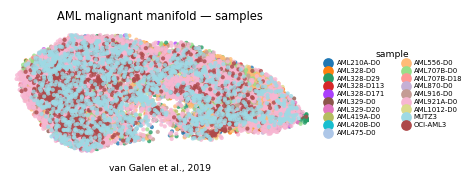

In [10]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('AML malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'van Galen et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])